#### 1. Inicial Inspection

Downloading the Dataset

In [ ]:
from pathlib import Path
import kagglehub

path = Path(kagglehub.dataset_download(
    "sergionefedov/layoff-survival-who-actually-gets-cut",
    output_dir="../data/layoff-survival",
))

print("Dataset salvo em:", path.resolve())

A. Data Dictionary 

**Dataset source**. The *Layoff Survival — Who Actually Gets Cut?* dataset was published on Kaggle by Sergey Nefedov. It contains **30,000 synthetic employee records** representing a company-wide layoff in which approximately **20%** of employees were cut. These are simulated data, not records of actual layoffs. 

**What each row represents.** Each row represents one simulated employee, with their attributes and layoff outcome

**The meaning, type and unit of each feature.**

| Feature | Meaning | Type | Unit / values |
|---|---|---|---|
| `employee_id` | Unique employee identifier | String (identifier) | No unit |
| `department` | Employee’s department | Categorical string | `engineering`, `sales`, `product`, `marketing`, `recruiting`, `support`, `g_and_a`, `research`, `data` |
| `cost_center_type` | Whether the employee’s area generates revenue | Categorical string | `revenue`, `support`, `cost_center` |
| `team_wind_down` | Whether the employee’s team or project is being eliminated in the reorganization | Binary integer | `1` = yes; `0` = no |
| `tenure_years` | Time employed by the company | Float | Years |
| `is_recent_hire` | Whether tenure is less than one year | Binary integer | `1` = yes; `0` = no |
| `performance_rating` | Most recent performance rating | Float | Rating scale from 1 to 5 |
| `on_pip` | Whether the employee is on a performance improvement plan | Binary integer | `1` = yes; `0` = no |
| `mgmt_layer` | Employee’s management category | Categorical string | `IC` (individual contributor), `manager`, `director` |
| `level` | Employee’s seniority level | Categorical string | `junior`, `mid`, `senior`, `staff`, `lead` |
| `salary_k_usd` | Annual salary | Integer | Thousands of USD per year |
| `high_salary` | Whether salary is in the top quartile | Binary integer | `1` = yes; `0` = no |
| `remote` | Whether the employee works primarily remotely | Binary integer | `1` = yes; `0` = no |
| `role_redundant` | Whether the role is duplicated after a merger or organizational overlap | Binary integer | `1` = yes; `0` = no |
| `laid_off` | **Target:** whether the employee was selected for the layoff | Binary integer | `1` = laid off; `0` = retained |

In [2]:
import pandas as pd

csv_path = "./data/layoff-survival/layoff_survival.csv"
df = pd.read_csv(csv_path)

print(f"\nDimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
display(df.head())


Dimensões: 30,000 linhas × 15 colunas


,employee_id,department,cost_center_type,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,mgmt_layer,level,salary_k_usd,high_salary,remote,role_redundant,laid_off
0,E000000,engineering,revenue,0,4.0,0,2.6,0,manager,mid,120,0,1,0,0
1,E000001,engineering,revenue,0,3.5,0,2.9,0,IC,mid,146,0,0,0,0
2,E000002,engineering,revenue,0,3.7,0,2.6,0,IC,senior,168,0,0,0,0
3,E000003,product,revenue,0,5.6,0,4.1,0,IC,staff,219,1,1,0,0
4,E000004,support,support,0,1.3,0,2.9,0,IC,junior,78,0,0,0,0


B. Quality

**Missing values.** The dataset contains no missing values.

In [3]:
import numpy as np

# 1. Missing values
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)

display(missing)

,missing_count,missing_pct
employee_id,0,0.0
department,0,0.0
cost_center_type,0,0.0
team_wind_down,0,0.0
tenure_years,0,0.0
is_recent_hire,0,0.0
performance_rating,0,0.0
on_pip,0,0.0
mgmt_layer,0,0.0
level,0,0.0


**Duplicates.** There are no exact duplicate rows, and each `employee_id` is unique. When `employee_id` is excluded, however, eight rows repeat the values of an earlier row across all remaining columns. These records may represent different employees with identical recorded attributes, so they should not be removed without further investigation.

In [4]:
# 2. Duplicates
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicated employee_id values:", df["employee_id"].duplicated().sum())

# Same employee attributes and outcome, disregarding the identifier.
print(
    "Duplicate rows excluding employee_id:",
    df.drop(columns="employee_id").duplicated().sum()
)

Exact duplicate rows: 0
Duplicated employee_id values: 0
Duplicate rows excluding employee_id: 8


**Impossible or Inconsistent Values.** The dataset contains no impossible or inconsistent values.

In [5]:
# 3. Impossible values and inconsistent derived columns
issues = {}

binary_columns = [
    "team_wind_down", "is_recent_hire", "on_pip",
    "high_salary", "remote", "role_redundant", "laid_off",
]
for col in binary_columns:
    issues[f"{col}: outside 0/1"] = ~df[col].isin([0, 1]) & df[col].notna()

allowed_categories = {
    "department": {
        "engineering", "sales", "product", "marketing", "recruiting",
        "support", "g_and_a", "research", "data",
    },
    "cost_center_type": {"revenue", "support", "cost_center"},
    "mgmt_layer": {"IC", "manager", "director"},
    "level": {"junior", "mid", "senior", "staff", "lead"},
}
for col, allowed in allowed_categories.items():
    issues[f"{col}: unknown category"] = ~df[col].isin(allowed) & df[col].notna()

issues["employee_id: missing or blank"] = (
    df["employee_id"].isna()
    | df["employee_id"].astype("string").str.strip().eq("").fillna(False)
)
issues["tenure_years: negative"] = df["tenure_years"] < 0
issues["performance_rating: outside 1–5"] = ~df[
    "performance_rating"
].between(1, 5) & df["performance_rating"].notna()
issues["salary_k_usd: nonpositive"] = df["salary_k_usd"] <= 0

# is_recent_hire is defined as tenure < 1 year.
issues["is_recent_hire: inconsistent with tenure"] = (
    df["is_recent_hire"].isin([0, 1])
    & df["tenure_years"].notna()
    & df["is_recent_hire"].ne(df["tenure_years"].lt(1).astype(int))
)

quality_issues = pd.DataFrame({
    "check": issues.keys(),
    "affected_rows": [mask.fillna(False).sum() for mask in issues.values()],
}).sort_values("affected_rows", ascending=False)

display(quality_issues)

,check,affected_rows
0,team_wind_down: outside 0/1,0
1,is_recent_hire: outside 0/1,0
2,on_pip: outside 0/1,0
3,high_salary: outside 0/1,0
4,remote: outside 0/1,0
5,role_redundant: outside 0/1,0
6,laid_off: outside 0/1,0
7,department: unknown category,0
8,cost_center_type: unknown category,0
9,mgmt_layer: unknown category,0


**Columns to Drop.**

| Column | Decision | Reason |
|---|---|---|
| `employee_id` | Drop | Identifier; it should not be used as a predictor. |
| `laid_off` | Separate as `y` | This is the target, not an input feature. |

C. Target

In [6]:
target = df["laid_off"]

# Verify if there are missing or unexpected values
print("Missing target values:", target.isna().sum())
print("Values found:", target.dropna().unique())

# Frequency of each class
class_counts = target.value_counts().reindex([0, 1], fill_value=0)
class_pct = (
    target.value_counts(normalize=True)
    .reindex([0, 1], fill_value=0)
    .mul(100)
)

target_summary = pd.DataFrame({
    "Class": ["0 — Retained", "1 — Laid off"],
    "Count": class_counts.values,
    "Percentage (%)": class_pct.values.round(2),
})

display(target_summary)

# Reason between majority and minority class
if class_counts.min() == 0:
    print("Imbalance ratio: undefined (one class is absent).")
else:
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")
    print(
        "The dataset is imbalanced."
        if imbalance_ratio >= 2
        else "The class distribution is relatively balanced."
    )

Missing target values: 0
Values found: [0 1]


,Class,Count,Percentage (%)
0,0 — Retained,23893,79.64
1,1 — Laid off,6107,20.36


Imbalance ratio: 3.91:1
The dataset is imbalanced.


**Frequency and Imbalance.** The target classes are imbalanced: the majority class has approximately 3.91 times as many observations as the minority class.

D. Train and Test

In [7]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df.drop(columns=["employee_id", "laid_off"])
y = df["laid_off"].astype(int)

# 80% temporary set, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

# 25% of the temporary set = 20% of the full dataset
# Final proportions: 60% train, 20% validation, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42,
)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(y_train), len(y_val), len(y_test)],
    "Laid off (1)": [y_train.sum(), y_val.sum(), y_test.sum()],
    "Laid off (%)": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2),
    ],
})

display(split_summary)

,Split,Rows,Laid off (1),Laid off (%)
0,Train,18000,3665,20.36
1,Validation,6000,1221,20.35
2,Test,6000,1221,20.35


#### 2. Univariate Analysis

A. Numerical Features

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ["tenure_years", "performance_rating", "salary_k_usd"]

# Descriptive statistics
summary = df[numeric_cols].describe().T.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std. deviation",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum",
})

summary["Missing"] = df[numeric_cols].isna().sum()
summary["Skewness"] = df[numeric_cols].skew()

# IQR rule: values outside [Q1 - 1.5 × IQR, Q3 + 1.5 × IQR]
summary["IQR"] = summary["Q3"] - summary["Q1"]
summary["IQR outliers"] = [
    (
        (df[col] < summary.loc[col, "Q1"] - 1.5 * summary.loc[col, "IQR"])
        | (df[col] > summary.loc[col, "Q3"] + 1.5 * summary.loc[col, "IQR"])
    ).sum()
    for col in numeric_cols
]

display(summary.round(2))

,Count,Mean,Std. deviation,Minimum,Q1,Median,Q3,Maximum,Missing,Skewness,IQR,IQR outliers
tenure_years,30000.0,4.38,3.10,0.1,2.1,3.7,5.9,25.0,0,1.43,3.8,950
performance_rating,30000.0,3.39,0.87,1.0,2.8,3.4,4.0,5.0,0,-0.16,1.2,0
salary_k_usd,30000.0,163.65,66.22,51.0,114.0,151.0,198.0,600.0,0,1.06,84.0,806


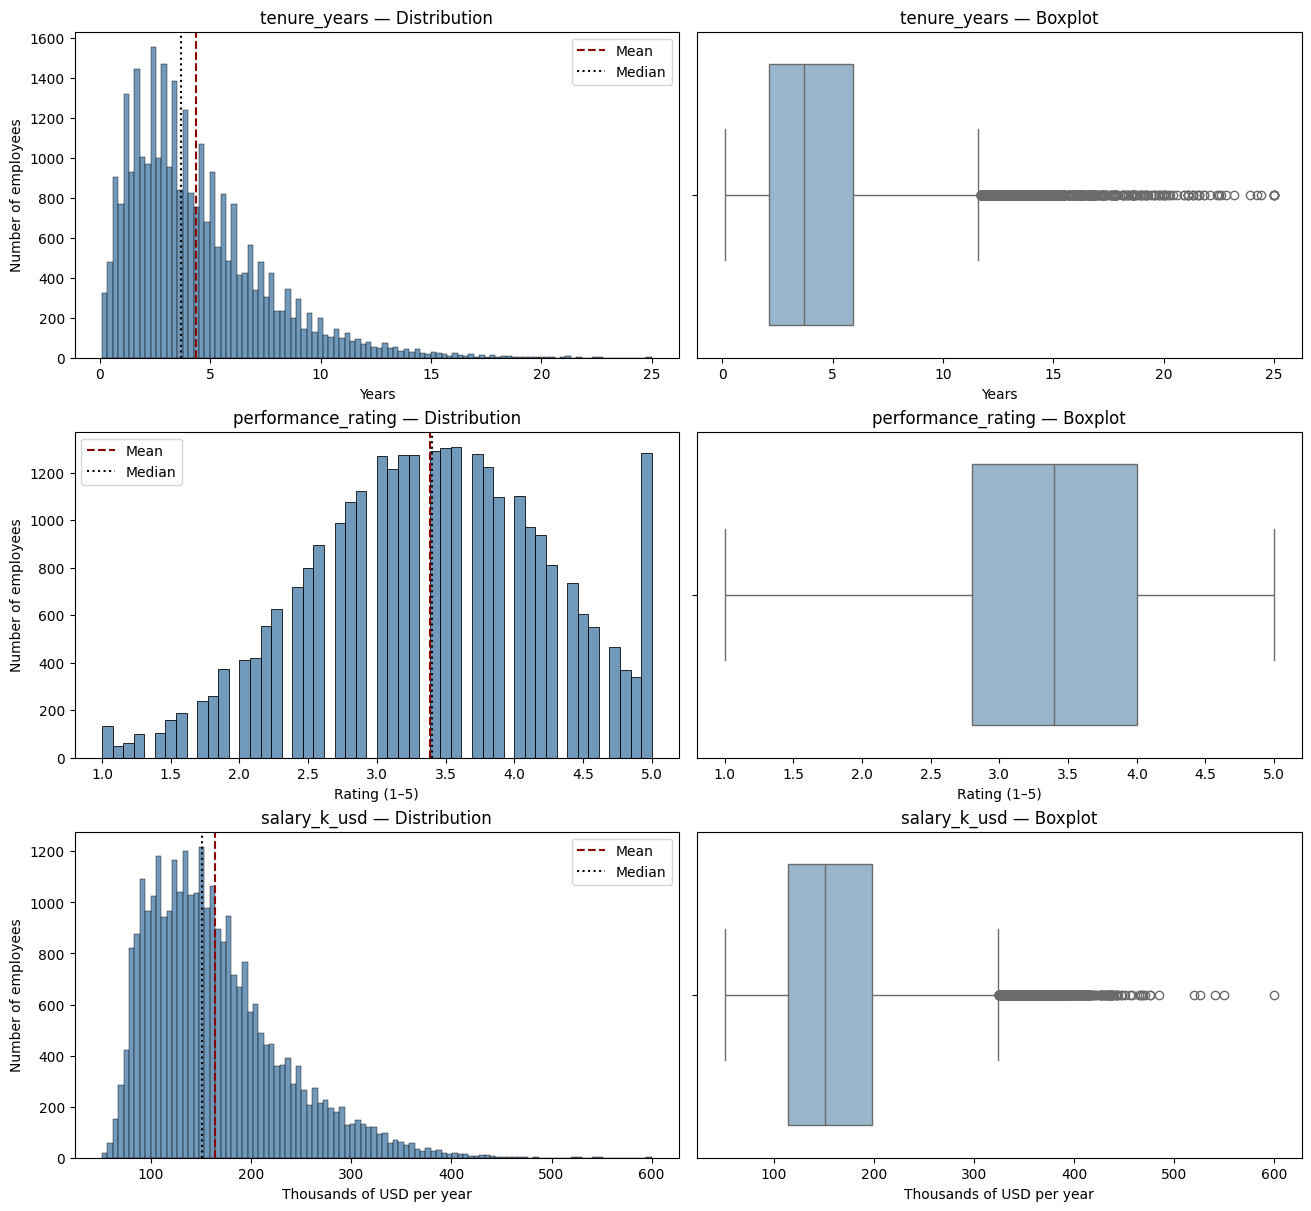

In [9]:
units = {
    "tenure_years": "Years",
    "performance_rating": "Rating (1–5)",
    "salary_k_usd": "Thousands of USD per year",
}

fig, axes = plt.subplots(
    nrows=len(numeric_cols),
    ncols=2,
    figsize=(13, 4 * len(numeric_cols)),
    constrained_layout=True,
)

for row, col in enumerate(numeric_cols):
    values = df[col].dropna()

    # Histogram: distribution shape and possible peaks
    sns.histplot(values, bins="auto", ax=axes[row, 0], color="#4277a5")
    axes[row, 0].axvline(
        values.mean(), color="darkred", linestyle="--", label="Mean"
    )
    axes[row, 0].axvline(
        values.median(), color="black", linestyle=":", label="Median"
    )
    axes[row, 0].set(
        title=f"{col} — Distribution",
        xlabel=units[col],
        ylabel="Number of employees",
    )
    axes[row, 0].legend()

    # Boxplot: quartiles, spread and potential outliers
    sns.boxplot(x=values, ax=axes[row, 1], color="#91b7d5")
    axes[row, 1].set(
        title=f"{col} — Boxplot",
        xlabel=units[col],
    )

plt.savefig("./figures/figure1.png", dpi=150)
plt.show()

All three numerical features have 30,000 observations and no missing values.

**Tenure.** `tenure_years` is concentrated at shorter durations, with a single broad peak around 2–3 years and a long right tail. Its mean (4.38 years) exceeds its median (3.7 years), consistent with positive skewness (1.43). The IQR rule flags 950 employees (3.17%) with tenure above 11.6 years as potential outliers. These values extend up to 25 years but are plausible employment durations.

**Performance rating.** `performance_rating` is broadly centered around 3.4, with a mean of 3.39 and a median of 3.4. Its skewness of −0.16 indicates only slight left skew. The histogram has one broad central peak and a noticeable concentration at the maximum rating of 5.0. No values fall outside the 1–5 scale, and none are flagged by the IQR rule.

**Salary.** `salary_k_usd` has a broad peak around USD 100,000–150,000 per year and a long right tail. Its mean (USD 163,650) exceeds its median (USD 151,000), consistent with positive skewness (1.06). The IQR rule flags 806 employees (2.69%) with salaries above USD 324,000 as potential outliers. The maximum is USD 600,000; 

B. Categorical Features

In [10]:
import math

categorical_cols = [
    "department",
    "cost_center_type",
    "mgmt_layer",
    "level",
    "team_wind_down",
    "is_recent_hire",
    "on_pip",
    "high_salary",
    "remote",
    "role_redundant",
]

binary_cols = {
    "team_wind_down",
    "is_recent_hire",
    "on_pip",
    "high_salary",
    "remote",
    "role_redundant",
}

# Descriptive rules for this report; they are not universal cutoffs.
RARE_PCT = 1.0
HIGH_CARDINALITY = 20

# Cardinality and missing values
categorical_summary = pd.DataFrame({
    "Feature": categorical_cols,
    "Cardinality": [df[col].nunique(dropna=True) for col in categorical_cols],
    "Missing": [df[col].isna().sum() for col in categorical_cols],
})

categorical_summary["High cardinality?"] = (
    categorical_summary["Cardinality"] > HIGH_CARDINALITY
)

display(categorical_summary)

# Count and percentage of every category
frequency_tables = {}

for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)
    percentages = counts / len(df) * 100

    table = pd.DataFrame({
        "Category": counts.index,
        "Count": counts.values,
        "Percentage (%)": percentages.values.round(2),
    })
    table["Rare (<1%)?"] = table["Percentage (%)"] < RARE_PCT

    frequency_tables[col] = table

    print(f"\n{col}")
    display(table)

,Feature,Cardinality,Missing,High cardinality?
0,department,9,0,False
1,cost_center_type,3,0,False
2,mgmt_layer,3,0,False
3,level,5,0,False
4,team_wind_down,2,0,False
5,is_recent_hire,2,0,False
6,on_pip,2,0,False
7,high_salary,2,0,False
8,remote,2,0,False
9,role_redundant,2,0,False



department


,Category,Count,Percentage (%),Rare (<1%)?
0,engineering,7255,24.18,False
1,sales,4888,16.29,False
2,support,3696,12.32,False
3,product,3041,10.14,False
4,marketing,2938,9.79,False
5,research,2381,7.94,False
6,g_and_a,2327,7.76,False
7,recruiting,1742,5.81,False
8,data,1732,5.77,False



cost_center_type


,Category,Count,Percentage (%),Rare (<1%)?
0,revenue,16916,56.39,False
1,support,6634,22.11,False
2,cost_center,6450,21.50,False


...

,Category,Count,Percentage (%),Rare (<1%)?
0,0,22487,74.96,False
1,1,7513,25.04,False



remote


,Category,Count,Percentage (%),Rare (<1%)?
0,0,17412,58.04,False
1,1,12588,41.96,False



role_redundant


,Category,Count,Percentage (%),Rare (<1%)?
0,0,26388,87.96,False
1,1,3612,12.04,False


No categorical predictor contains a rare category - less than 1% of observations - or has high cardinality - more than 20 distinct categories. 

#### 3. Bivariate and Multivariate Analysis

A. Numerical × Numerical 

,tenure_years,performance_rating,salary_k_usd
tenure_years,1.000,0.012,0.004
performance_rating,0.012,1.000,-0.002
salary_k_usd,0.004,-0.002,1.000


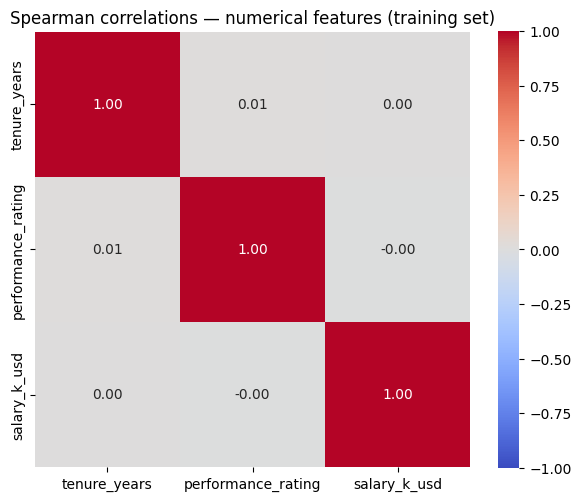

,Feature 1,Feature 2,Spearman correlation,Potentially redundant?
0,tenure_years,performance_rating,0.012062,False
1,tenure_years,salary_k_usd,0.003557,False
2,performance_rating,salary_k_usd,-0.001938,False


In [14]:
import itertools

numeric_cols = ["tenure_years", "performance_rating", "salary_k_usd"]

# Correlation matrix: training data only
corr = X_train[numeric_cols].corr(method="spearman")
display(corr.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
)
plt.title("Spearman correlations — numerical features (training set)")
plt.tight_layout()
plt.savefig("./figures/figure2.png", dpi=150)
plt.show()

# List every pair and flag strong correlations for review.
# 0.80 is a screening rule, not an automatic reason to drop a feature.
pairs = pd.DataFrame([
    {
        "Feature 1": a,
        "Feature 2": b,
        "Spearman correlation": corr.loc[a, b],
        "Potentially redundant?": abs(corr.loc[a, b]) >= 0.80,
    }
    for a, b in itertools.combinations(numeric_cols, 2)
]).sort_values(
    "Spearman correlation", key=lambda values: values.abs(), ascending=False
)

display(pairs)

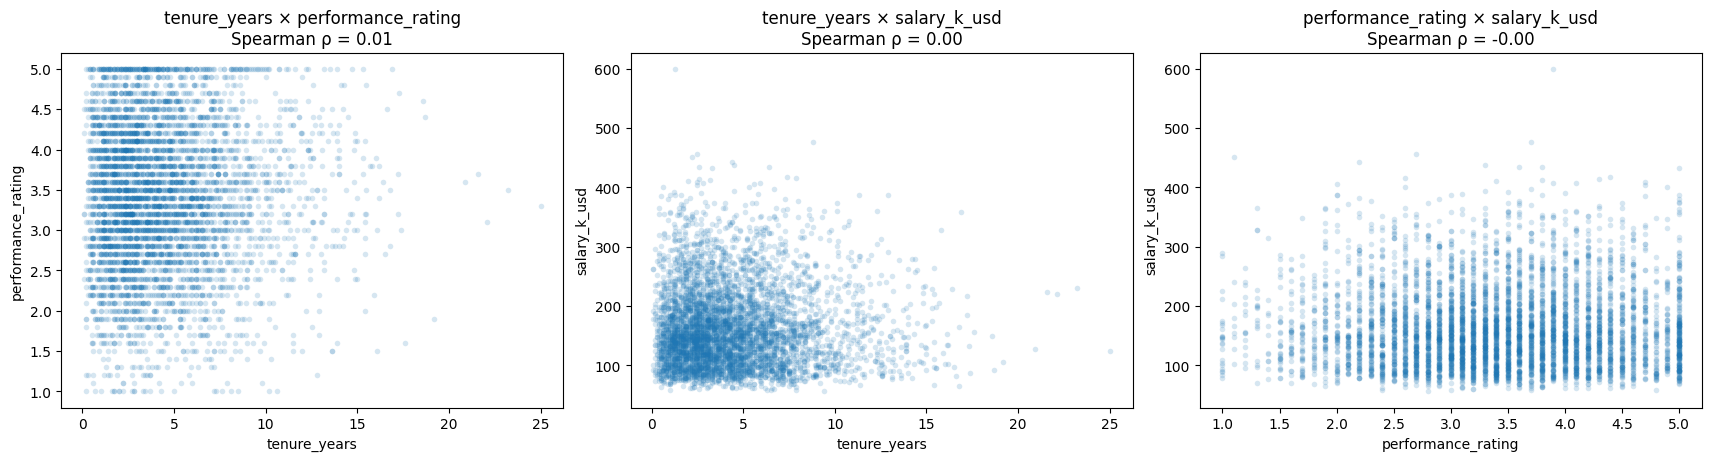

In [15]:
plot_data = X_train[numeric_cols].sample(
    n=min(5_000, len(X_train)),
    random_state=42,
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)

for ax, (x, y) in zip(axes, itertools.combinations(numeric_cols, 2)):
    sns.scatterplot(
        data=plot_data,
        x=x,
        y=y,
        alpha=0.18,
        s=16,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{x} × {y}\nSpearman ρ = {corr.loc[x, y]:.2f}")

plt.savefig("./figures/figure3.png", dpi=150)
plt.show()

Spearman’s rank correlation was used to examine relationships among `tenure_years`, `performance_rating`, and `salary_k_usd` in the training set. This measure was selected because tenure and salary are right-skewed and contain high values, while the analysis does not assume that any relationship must be linear. The correlations shown in Figure 2 are close to zero for all three pairs: tenure and performance rating (ρ = 0.01), tenure and salary (ρ ≈ 0.00), and performance rating and salary (ρ ≈ 0.00). The scatter plots likewise show no clear increasing or decreasing pattern. Therefore, no strong monotonic relationship or redundant pair was identified among these numerical predictors. Correlations near zero do not rule out more complex, non-monotonic relationships.

B. Categorical x Target

In [16]:
categorical_cols = [
    "department",
    "cost_center_type",
    "mgmt_layer",
    "level",
    "team_wind_down",
    "is_recent_hire",
    "on_pip",
    "high_salary",
    "remote",
    "role_redundant",
]

binary_cols = {
    "team_wind_down",
    "is_recent_hire",
    "on_pip",
    "high_salary",
    "remote",
    "role_redundant",
}

# Rejoin predictors and target by their original row indices for analysis.
analysis = X_train[categorical_cols].copy()
analysis["laid_off"] = y_train

overall_layoff_pct = analysis["laid_off"].mean() * 100
print(f"Overall training-set layoff rate: {overall_layoff_pct:.2f}%")

category_tables = {}

for col in categorical_cols:
    table = (
        analysis.groupby(col, dropna=False)["laid_off"]
        .agg(
            employees="size",
            laid_off="sum",
            layoff_rate="mean",
        )
        .reset_index()
        .rename(columns={col: "category"})
    )

    table["retained"] = table["employees"] - table["laid_off"]
    table["laid_off_pct"] = table["layoff_rate"] * 100
    table["retained_pct"] = 100 - table["laid_off_pct"]

    table = table[
        ["category", "employees", "retained",
         "laid_off", "retained_pct", "laid_off_pct"]
    ].sort_values("laid_off_pct", ascending=False)

    category_tables[col] = table

    print(f"\n{col}")
    display(table.round(2))

Overall training-set layoff rate: 20.36%

department


,category,employees,retained,laid_off,retained_pct,laid_off_pct
6,research,1452,895,557,61.64,38.36
5,recruiting,1065,665,400,62.44,37.56
2,g_and_a,1412,898,514,63.60,36.40
3,marketing,1795,1328,467,73.98,26.02
8,support,2219,1710,509,77.06,22.94
0,data,1001,873,128,87.21,12.79
4,product,1796,1569,227,87.36,12.64
7,sales,2882,2530,352,87.79,12.21
1,engineering,4378,3867,511,88.33,11.67



cost_center_type


,category,employees,retained,laid_off,retained_pct,laid_off_pct
0,cost_center,3929,2458,1471,62.56,37.44
2,support,4014,3038,976,75.69,24.31
1,revenue,10057,8839,1218,87.89,12.11



mgmt_layer


...

,category,employees,retained,laid_off,retained_pct,laid_off_pct
1,1,4495,3483,1012,77.49,22.51
0,0,13505,10852,2653,80.36,19.64



remote


,category,employees,retained,laid_off,retained_pct,laid_off_pct
0,0,10420,8291,2129,79.57,20.43
1,1,7580,6044,1536,79.74,20.26



role_redundant


,category,employees,retained,laid_off,retained_pct,laid_off_pct
1,1,2188,1486,702,67.92,32.08
0,0,15812,12849,2963,81.26,18.74


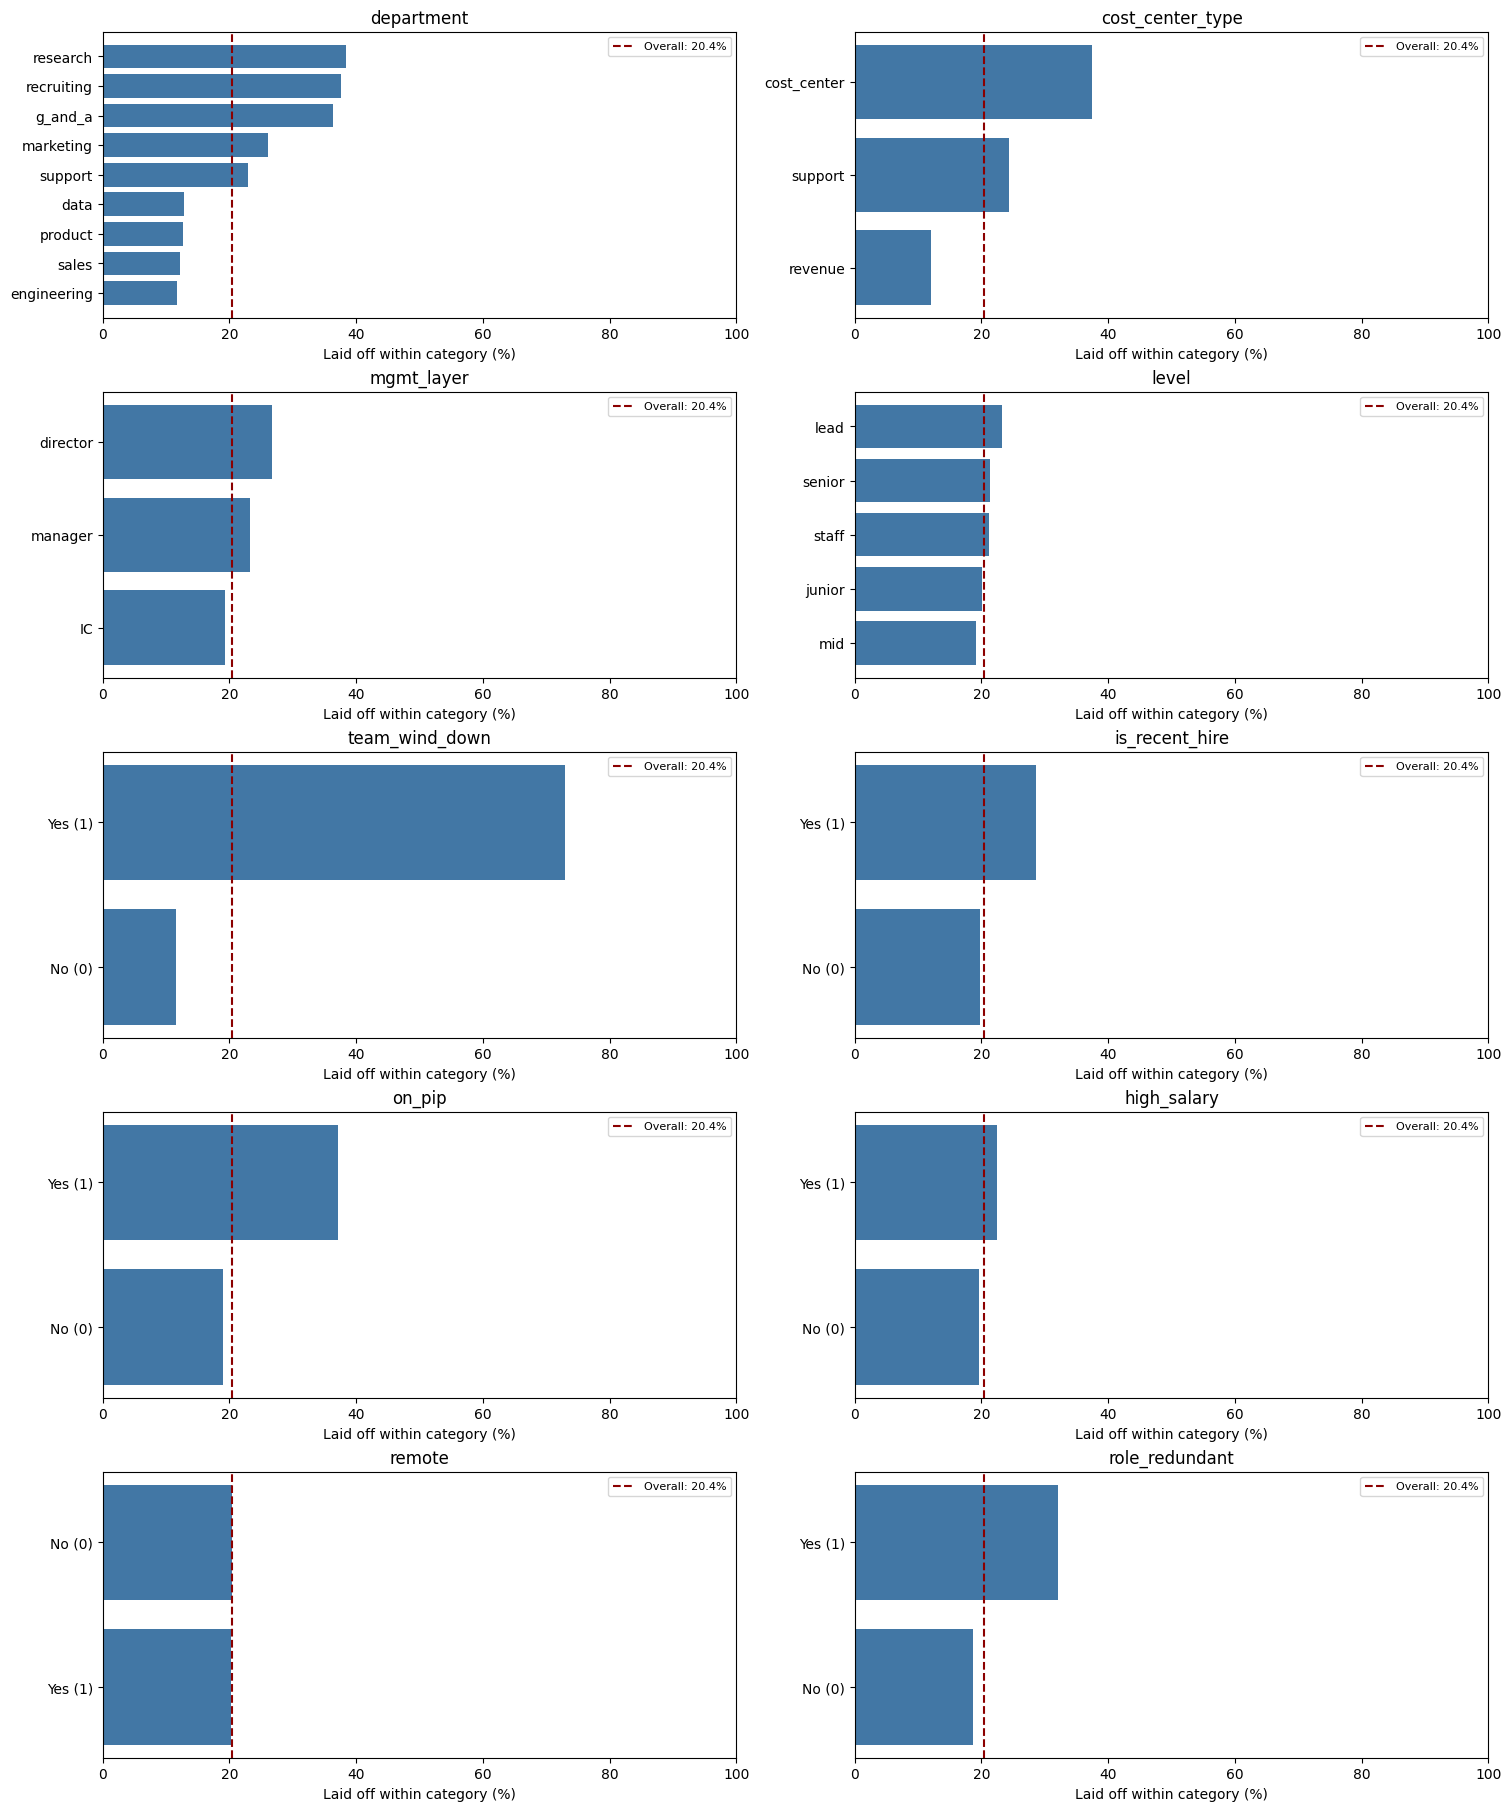

In [18]:
ncols = 2
nrows = math.ceil(len(categorical_cols) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 3.6 * nrows),
    constrained_layout=True,
)

for ax, col in zip(axes.flat, categorical_cols):
    table = category_tables[col]

    def label(value):
        if pd.isna(value):
            return "Missing"
        if col in binary_cols:
            return {0: "No (0)", 1: "Yes (1)"}.get(value, str(value))
        return str(value)

    labels = table["category"].map(label)

    ax.barh(labels, table["laid_off_pct"], color="#4277a5")
    ax.axvline(
        overall_layoff_pct,
        color="darkred",
        linestyle="--",
        label=f"Overall: {overall_layoff_pct:.1f}%",
    )
    ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlabel("Laid off within category (%)")
    ax.set_xlim(0, 100)
    ax.legend(fontsize=8)

for ax in list(axes.flat)[len(categorical_cols):]:
    ax.set_visible(False)

plt.savefig("./figures/figure4.png", dpi=150)
plt.show()

Figure 4 shows the proportion of employees laid off within each category in the training set. The overall layoff rate was approximately 20.4%. The largest difference appeared for `team_wind_down`: about 73% of employees whose teams were being eliminated were laid off, compared with about 12% of those whose teams were not. Layoff rates were also higher among employees in cost centers (about 37%) than in revenue-generating areas (about 12%). Employees on a performance improvement plan and those in redundant roles had higher layoff rates than their respective comparison groups.

Across departments, research, recruiting, and general and administrative roles had the highest layoff rates, while engineering, sales, product, and data had the lowest. Recent hires had a higher layoff rate than other employees. Differences by management layer and seniority level were smaller, and remote and non-remote employees had nearly identical rates. These are descriptive associations, not evidence that a feature caused a layoff. Before using organizational features such as `team_wind_down` and `role_redundant` for prediction, their availability at the intended prediction time should be confirmed to avoid target leakage.

C. Numerical × Categorical

In [19]:
numeric_cols = ["tenure_years", "performance_rating", "salary_k_usd"]

categorical_cols = [
    "department", "cost_center_type", "mgmt_layer", "level",
    "team_wind_down", "is_recent_hire", "on_pip",
    "high_salary", "remote", "role_redundant",
]

binary_cols = {
    "team_wind_down", "is_recent_hire", "on_pip",
    "high_salary", "remote", "role_redundant",
}

# Use training data only.
analysis = X_train[numeric_cols + categorical_cols].copy()

for numeric in numeric_cols:
    print(f"\n### {numeric}")

    for categorical in categorical_cols:
        grouped = (
            analysis.groupby(categorical, dropna=False)[numeric]
            .agg(
                count="count",
                median="median",
                q1=lambda s: s.quantile(0.25),
                q3=lambda s: s.quantile(0.75),
            )
            .reset_index()
            .rename(columns={categorical: "category"})
        )
        grouped["IQR"] = grouped["q3"] - grouped["q1"]

        print(f"\nGrouped by {categorical}")
        display(grouped.round(2))


### tenure_years

Grouped by department


,category,count,median,q1,q3,IQR
0,data,1001,3.8,2.2,5.8,3.6
1,engineering,4378,3.6,2.1,5.8,3.7
2,g_and_a,1412,3.7,2.1,5.9,3.8
3,marketing,1795,3.7,2.1,5.9,3.8
4,product,1796,3.8,2.2,6.0,3.8
5,recruiting,1065,3.7,2.2,5.8,3.6
6,research,1452,3.7,2.1,6.1,4.0
7,sales,2882,3.6,2.2,5.8,3.6
8,support,2219,3.6,2.1,5.9,3.8



Grouped by cost_center_type


,category,count,median,q1,q3,IQR
0,cost_center,3929,3.7,2.1,5.9,3.8
1,revenue,10057,3.7,2.2,5.8,3.6
2,support,4014,3.6,2.1,5.9,3.8



Grouped by mgmt_layer


...

,category,count,median,q1,q3,IQR
0,0,13505,133.0,104.0,160.0,56.0
1,1,4495,243.0,216.0,284.0,68.0



Grouped by remote


,category,count,median,q1,q3,IQR
0,0,10420,152.0,114.0,198.0,84.0
1,1,7580,149.0,113.0,197.0,84.0



Grouped by role_redundant


,category,count,median,q1,q3,IQR
0,0,15812,151.0,114.0,197.0,83.0
1,1,2188,150.0,113.0,198.0,85.0


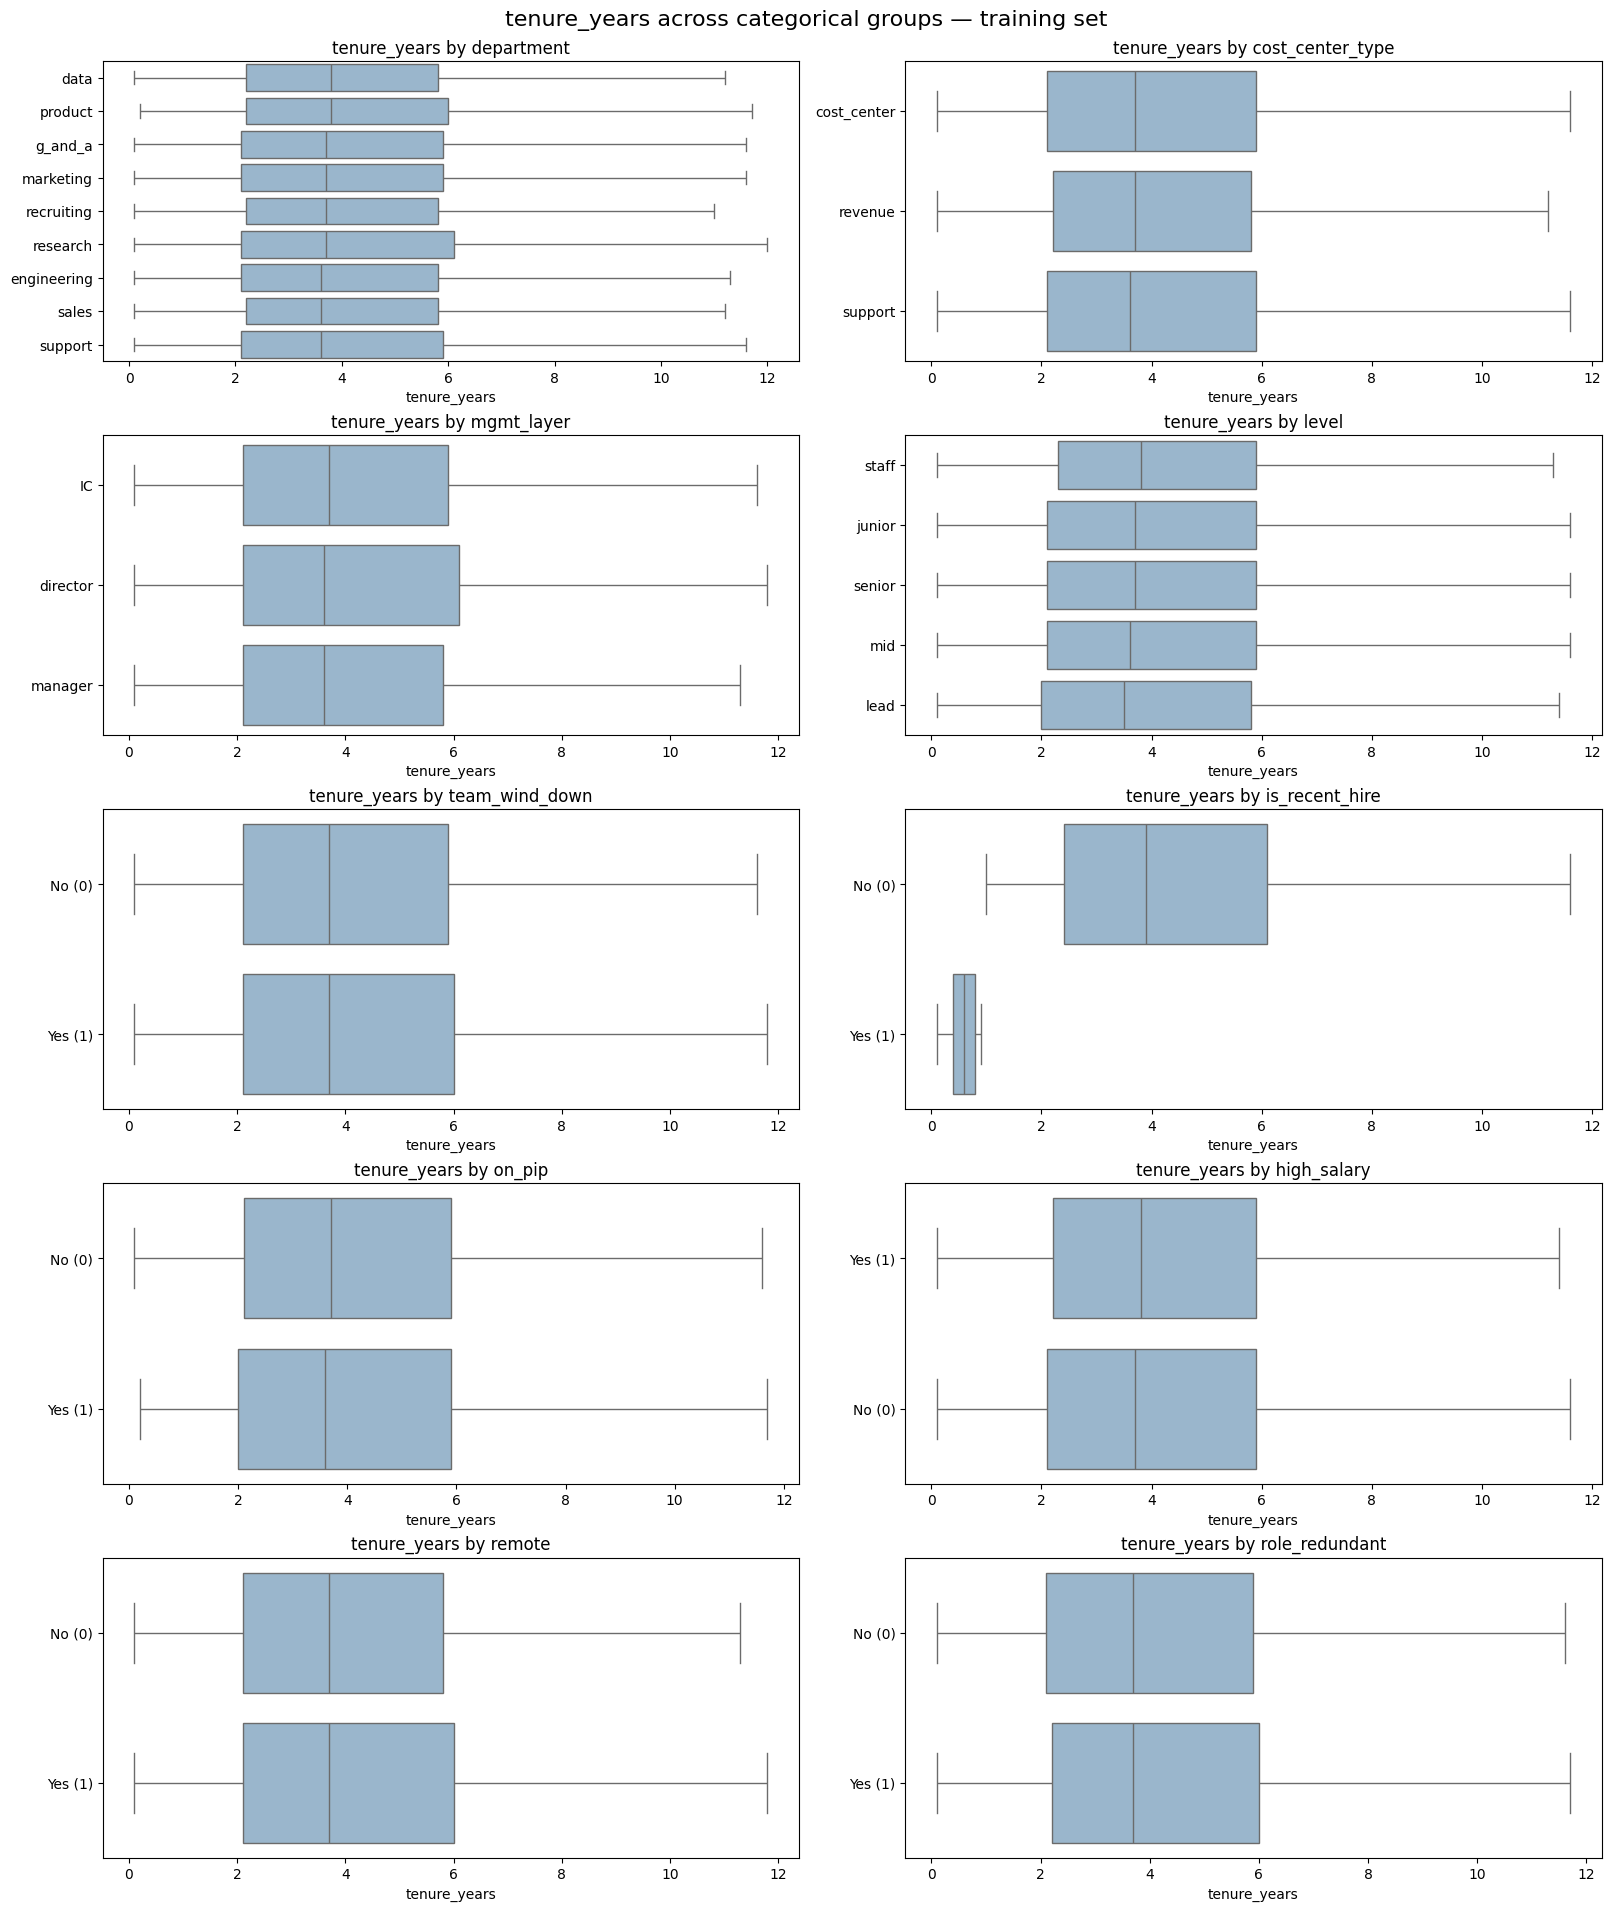

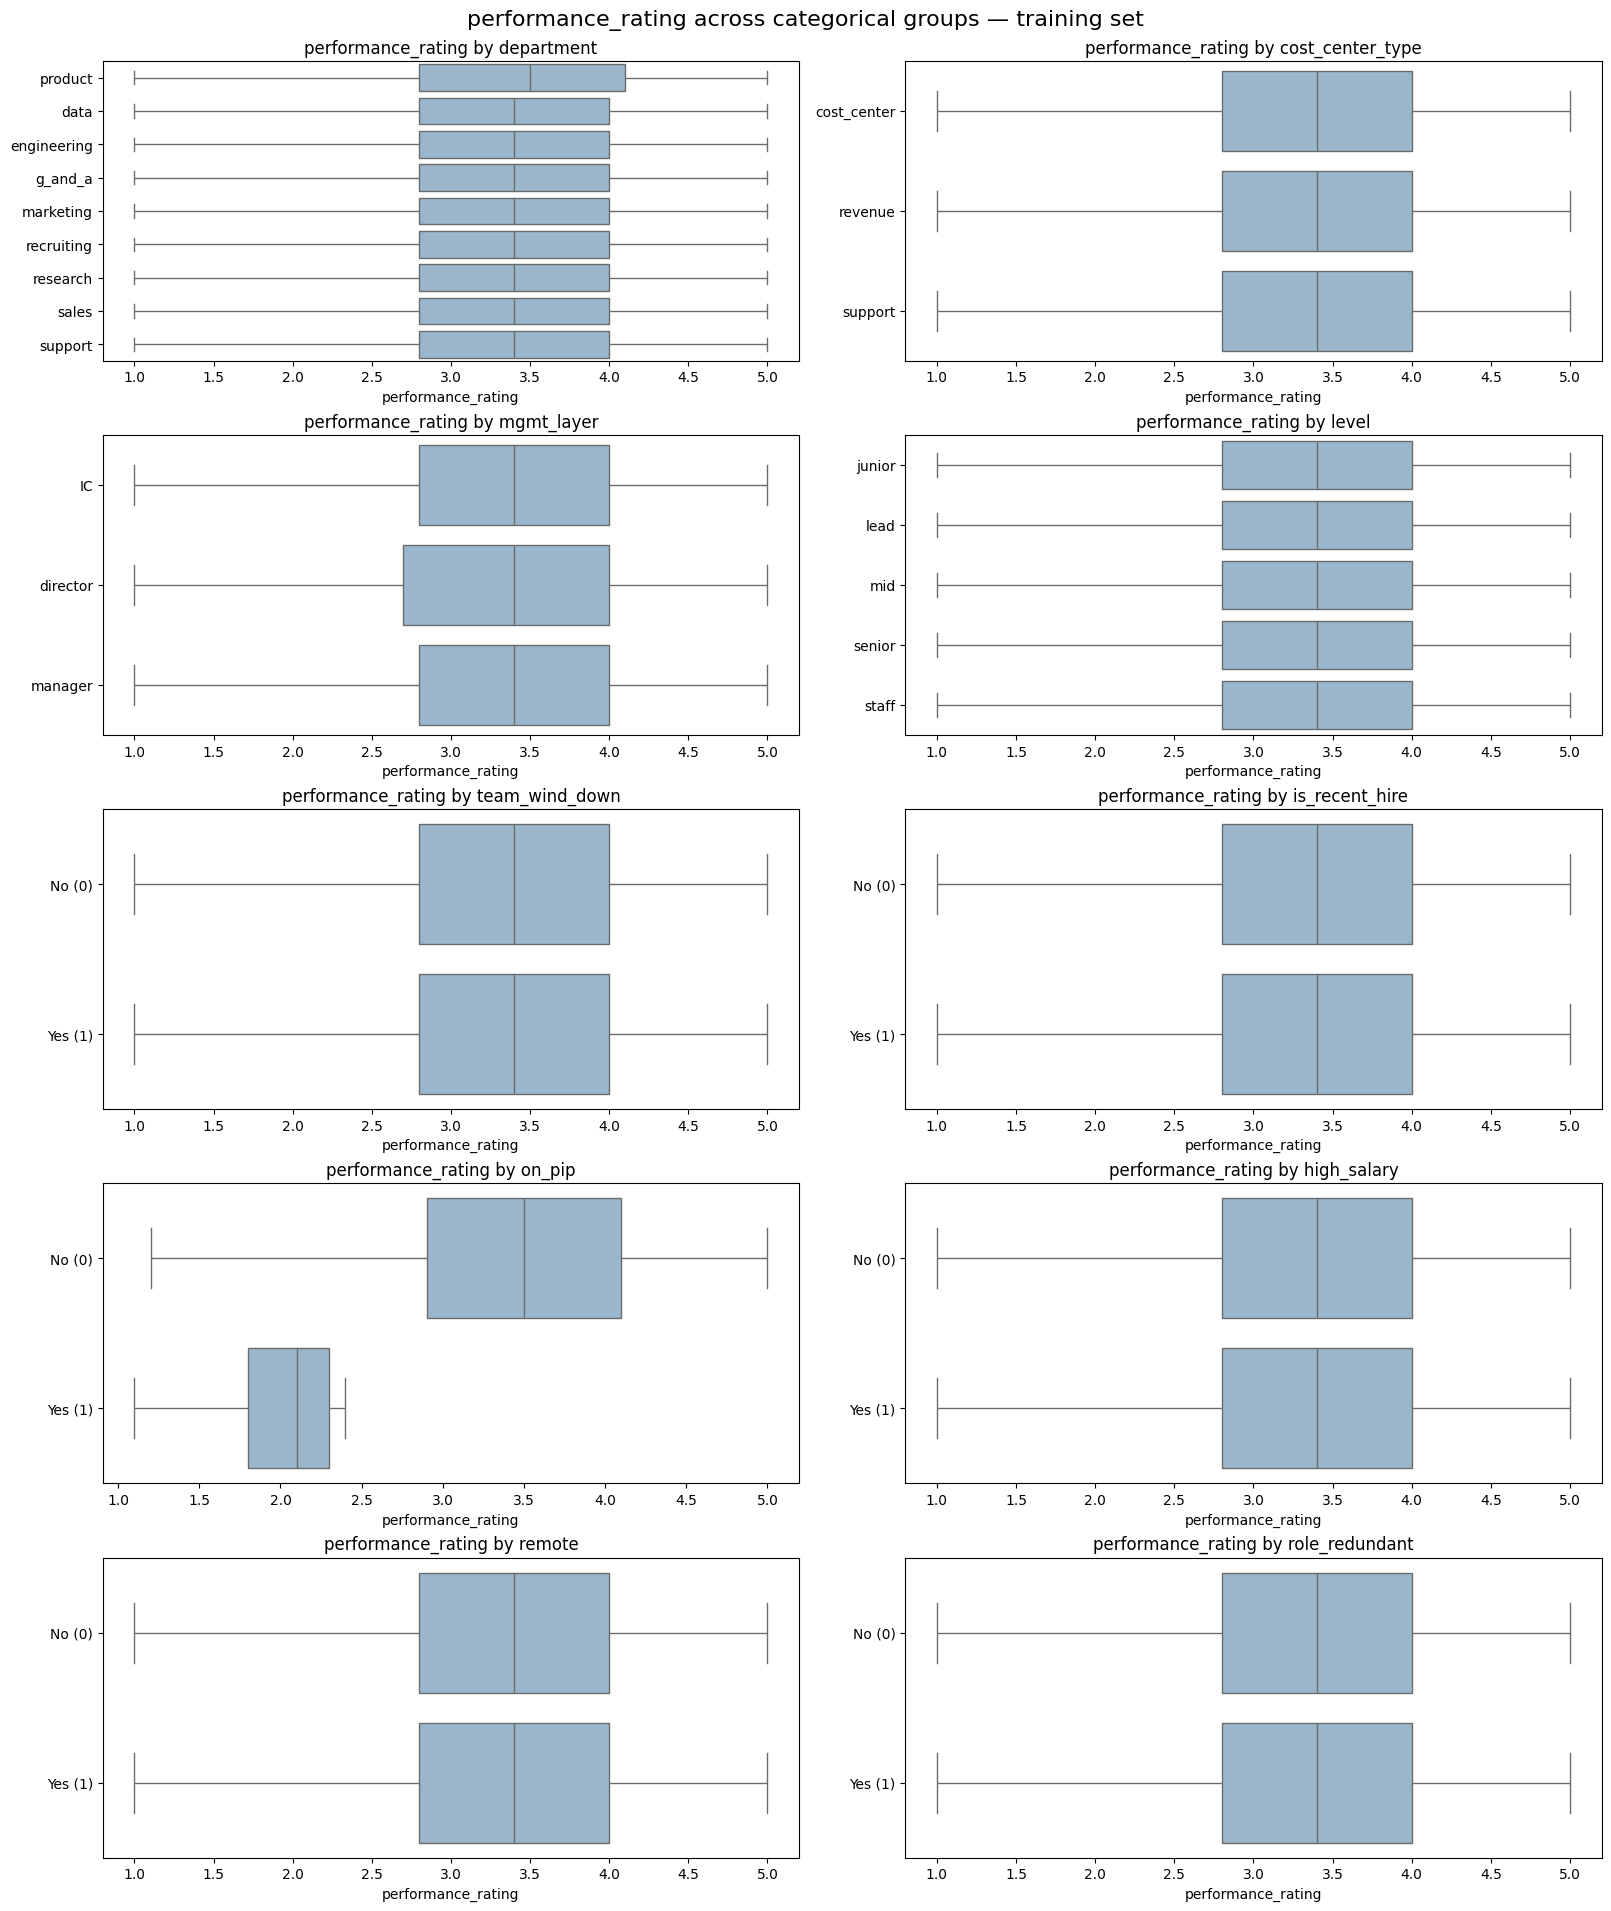

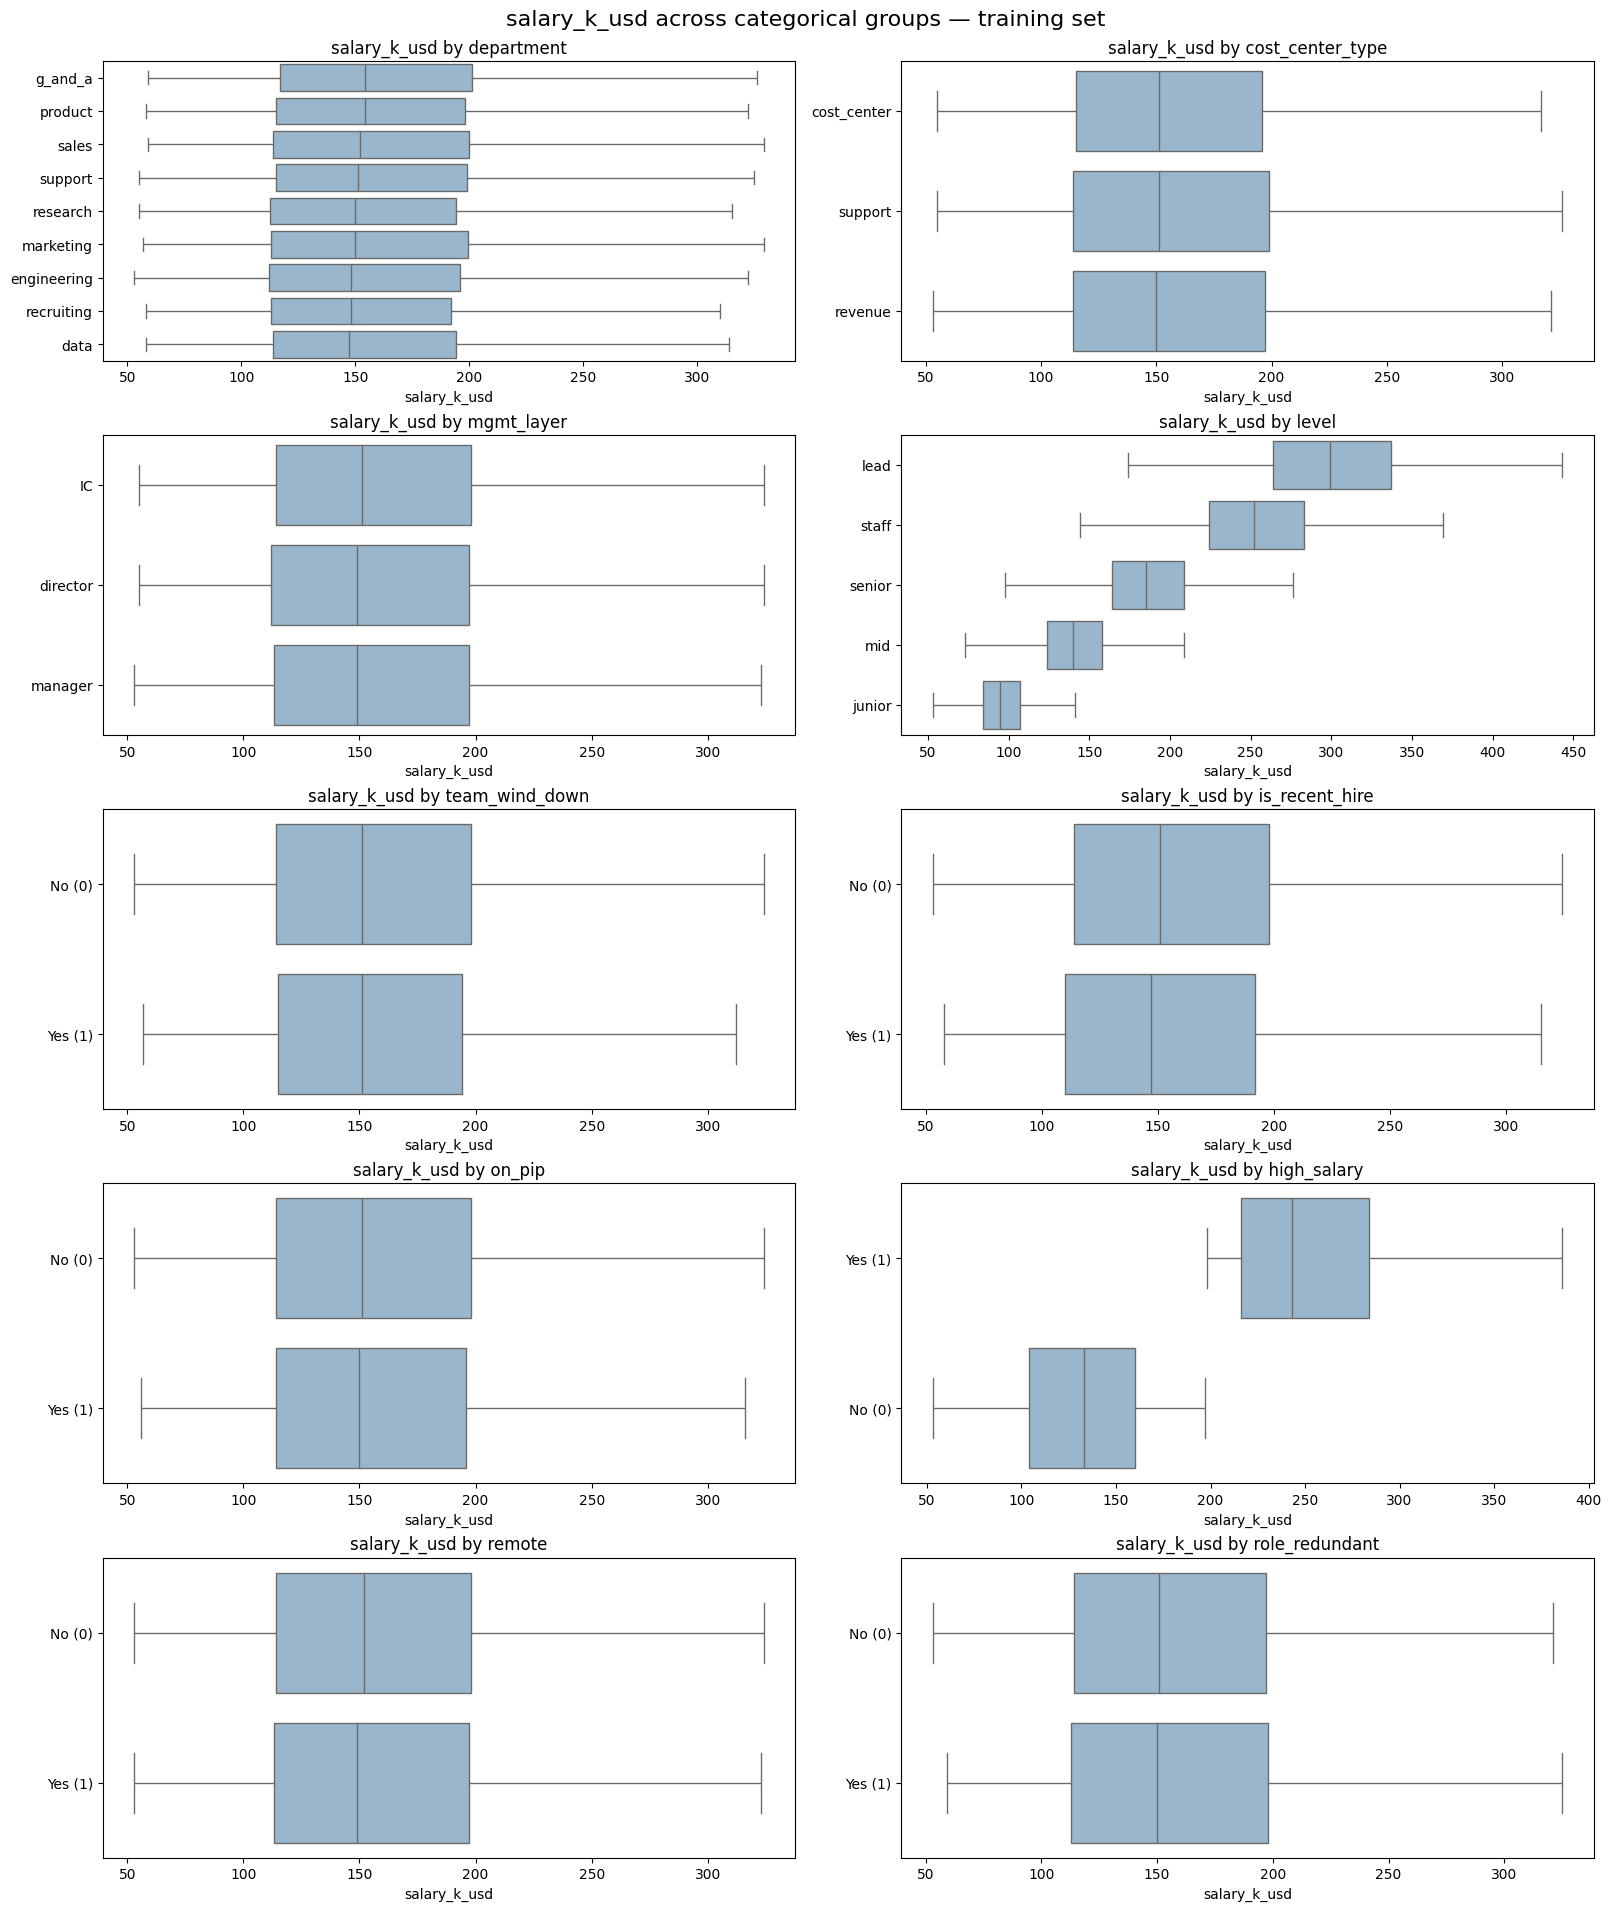

In [22]:
for numeric in numeric_cols:
    fig, axes = plt.subplots(
        5, 2, figsize=(16, 19), constrained_layout=True
    )

    for ax, categorical in zip(axes.flat, categorical_cols):
        plot_data = analysis[[numeric, categorical]].copy()

        def category_label(value):
            if pd.isna(value):
                return "Missing"
            if categorical in binary_cols:
                return {0: "No (0)", 1: "Yes (1)"}.get(value, str(value))
            return str(value)

        plot_data["group"] = plot_data[categorical].map(category_label)

        # Put groups with the highest median at the top.
        order = (
            plot_data.groupby("group")[numeric]
            .median()
            .sort_values(ascending=False)
            .index
        )

        sns.boxplot(
            data=plot_data,
            x=numeric,
            y="group",
            order=order,
            color="#91b7d5",
            showfliers=False,
            ax=ax,
        )
        ax.set_title(f"{numeric} by {categorical}")
        ax.set_xlabel(numeric)
        ax.set_ylabel("")

    fig.suptitle(
        f"{numeric} across categorical groups — training set",
        fontsize=16,
    )
    plt.savefig(f"./figures/figure5_{numeric}.png", dpi=150)
    plt.show()

The grouped boxplots compare the location and spread of each numerical feature across categorical groups in the training set. For `tenure_years`, most groups have similar medians and interquartile ranges. The clear exception is `is_recent_hire`: employees marked as recent hires have tenure below one year, as expected from the definition of that feature. No other categorical predictor shows a substantial separation in tenure.

For `performance_rating`, employees on a performance improvement plan (`on_pip = 1`) have a markedly lower median and a narrower interquartile range than employees who are not on a plan. Performance ratings otherwise have similar medians and spreads across departments, cost center types, management layers, seniority levels, and the other binary groups.

For `salary_k_usd`, seniority level shows the clearest difference: median salary rises from junior through lead, and the spread is generally wider at higher levels. Employees marked `high_salary = 1` also have higher salaries by definition, so this separation is expected. Salary distributions across the remaining categorical groups largely overlap, although departmental medians differ modestly. Overall, the most pronounced group differences are tied to features that directly describe or are derived from the numerical variable being plotted.

#### 4. Prepocessing

A. Strategies

| Step | Finding | Strategy |
|---|---|---|
| Missing values | The three numerical features had no missing values in the audit. | Keep a median imputer as a safeguard for future numerical inputs; represent a missing text category as `"Missing"`. Fit both on training data only. |
| Outliers | The IQR rule flagged 950 tenure values and 806 salary values, but their observed ranges are plausible. | Keep these records. An IQR flag alone is not evidence of an error. |
| Categorical encoding | The text predictors have low cardinality; `level` has named categories but no demonstrated equal spacing between them. | One-hot encode the four text predictors. Leave binary predictors as `0/1`. |
| New category in validation or test | A category may appear that was absent from training. | Use `handle_unknown="ignore"`: the encoder retains the columns learned during training and represents the unseen category with zeros in that feature’s encoded columns. ([scikit-learn 1.9.1 documentation][1]) |
| Scaling | Tenure, rating, and salary have different numerical ranges. `salary_k_usd` is **51–600 thousand USD**, rather than 51,000–600,000 in the stored column. | Standardize the three continuous features so their scales are comparable for neural network training. Keep binary and one-hot features at `0/1`. |

[1]: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html?utm_source=chatgpt.com "OneHotEncoder"

The preprocessing strategy was defined from the exploratory analysis and fitted using the training set only. Numerical features were standardized because tenure, performance rating, and annual salary were recorded on different scales, which could affect neural network optimization. The values flagged by the IQR rule for tenure and salary were retained because they were plausible and had not been identified as data errors. Text categories were one-hot encoded because they had low cardinality, while binary features retained their 0/1 representation. Median imputation for numerical features and an explicit “Missing” category for text features were included to handle missing inputs consistently. Categories appearing for the first time in validation or test data are handled by the fitted encoder without changing the number or order of input features.

In [27]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path("code").resolve()))
from preprocessing import fit_transform_splits

preprocessor, X_train_ready, X_val_ready, X_test_ready = (
    fit_transform_splits(X_train, X_val, X_test)
)

Train: shape=(18000, 29), NaN values=0
Validation: shape=(6000, 29), NaN values=0
Test: shape=(6000, 29), NaN values=0
Final feature count: 29
Feature names:
  numeric__tenure_years
  numeric__performance_rating
  numeric__salary_k_usd
  categorical__department_data
  categorical__department_engineering
  categorical__department_g_and_a
  categorical__department_marketing
  categorical__department_product
  categorical__department_recruiting
  categorical__department_research
  categorical__department_sales
  categorical__department_support
  categorical__cost_center_type_cost_center
  categorical__cost_center_type_revenue
  categorical__cost_center_type_support
  categorical__mgmt_layer_IC
  categorical__mgmt_layer_director
  categorical__mgmt_layer_manager
  categorical__level_junior
  categorical__level_lead
  categorical__level_mid
  categorical__level_senior
  categorical__level_staff
  binary__team_wind_down
  binary__is_recent_hire
  binary__on_pip
  binary__high_salary
  binary

B. Dimensionality Reduction

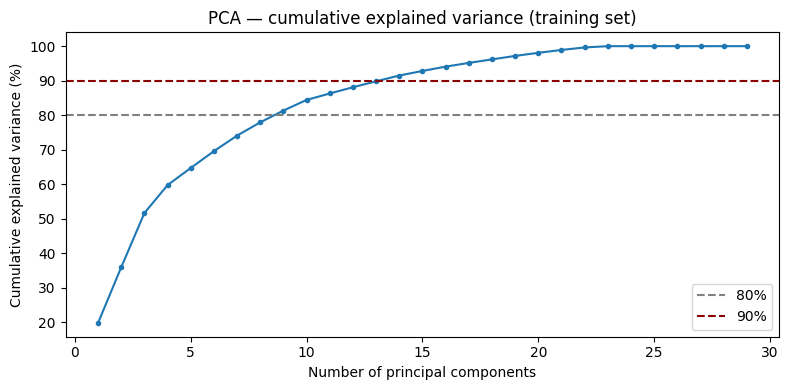

PC1 variance: 19.7%
PC2 variance: 16.2%
First two PCs combined: 35.9%
Components needed for 80% variance: 9
Components needed for 90% variance: 14

Largest absolute PC1 coefficients:


,PC1
numeric__salary_k_usd,0.888
binary__high_salary,0.328
categorical__level_junior,-0.228
categorical__level_staff,0.128
categorical__level_mid,-0.113
categorical__level_lead,0.108
categorical__level_senior,0.104
numeric__tenure_years,0.017
categorical__department_engineering,-0.007
binary__is_recent_hire,-0.007



Largest absolute PC2 coefficients:


,PC2
numeric__performance_rating,0.788
numeric__tenure_years,0.606
binary__on_pip,-0.096
binary__is_recent_hire,-0.053
numeric__salary_k_usd,-0.012
binary__remote,0.012
categorical__cost_center_type_revenue,0.006
categorical__department_product,0.005
categorical__cost_center_type_cost_center,-0.004
categorical__department_g_and_a,-0.003


In [25]:
from sklearn.decomposition import PCA

feature_names = preprocessor.get_feature_names_out()

pca = PCA(svd_solver="full")
pca.fit(X_train_ready)  # Full training set; no validation or test data

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o",
    markersize=3,
)
ax.axhline(80, color="gray", linestyle="--", label="80%")
ax.axhline(90, color="darkred", linestyle="--", label="90%")
ax.set(
    title="PCA — cumulative explained variance (training set)",
    xlabel="Number of principal components",
    ylabel="Cumulative explained variance (%)",
)
ax.legend()
plt.tight_layout()
plt.savefig("./figures/figure6.png", dpi=150)
plt.show()

print(f"PC1 variance: {pca.explained_variance_ratio_[0]:.1%}")
print(f"PC2 variance: {pca.explained_variance_ratio_[1]:.1%}")
print(f"First two PCs combined: {cumulative_variance[1]:.1%}")

for threshold in (0.80, 0.90):
    n_components = np.searchsorted(cumulative_variance, threshold) + 1
    print(f"Components needed for {threshold:.0%} variance: {n_components}")

# Largest positive and negative coefficients for the first two components.
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=feature_names,
    columns=["PC1", "PC2"],
)

for component in ["PC1", "PC2"]:
    print(f"\nLargest absolute {component} coefficients:")
    display(
        loadings[[component]]
        .assign(abs_coefficient=lambda t: t[component].abs())
        .sort_values("abs_coefficient", ascending=False)
        .head(10)
        .drop(columns="abs_coefficient")
        .round(3)
    )

c:\Users\giuli\OneDrive - Insper - Institudo de Ensino e Pesquisa\Documentos\insper\RedesNeurais\neuralNetworks-Project\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Projection sample: 5,000 training employees
Sample layoff rate: 20.4%


c:\Users\giuli\OneDrive - Insper - Institudo de Ensino e Pesquisa\Documentos\insper\RedesNeurais\neuralNetworks-Project\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\giuli\OneDrive - Insper - Institudo de Ensino e Pesquisa\Documentos\insper\RedesNeurais\neuralNetworks-Project\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


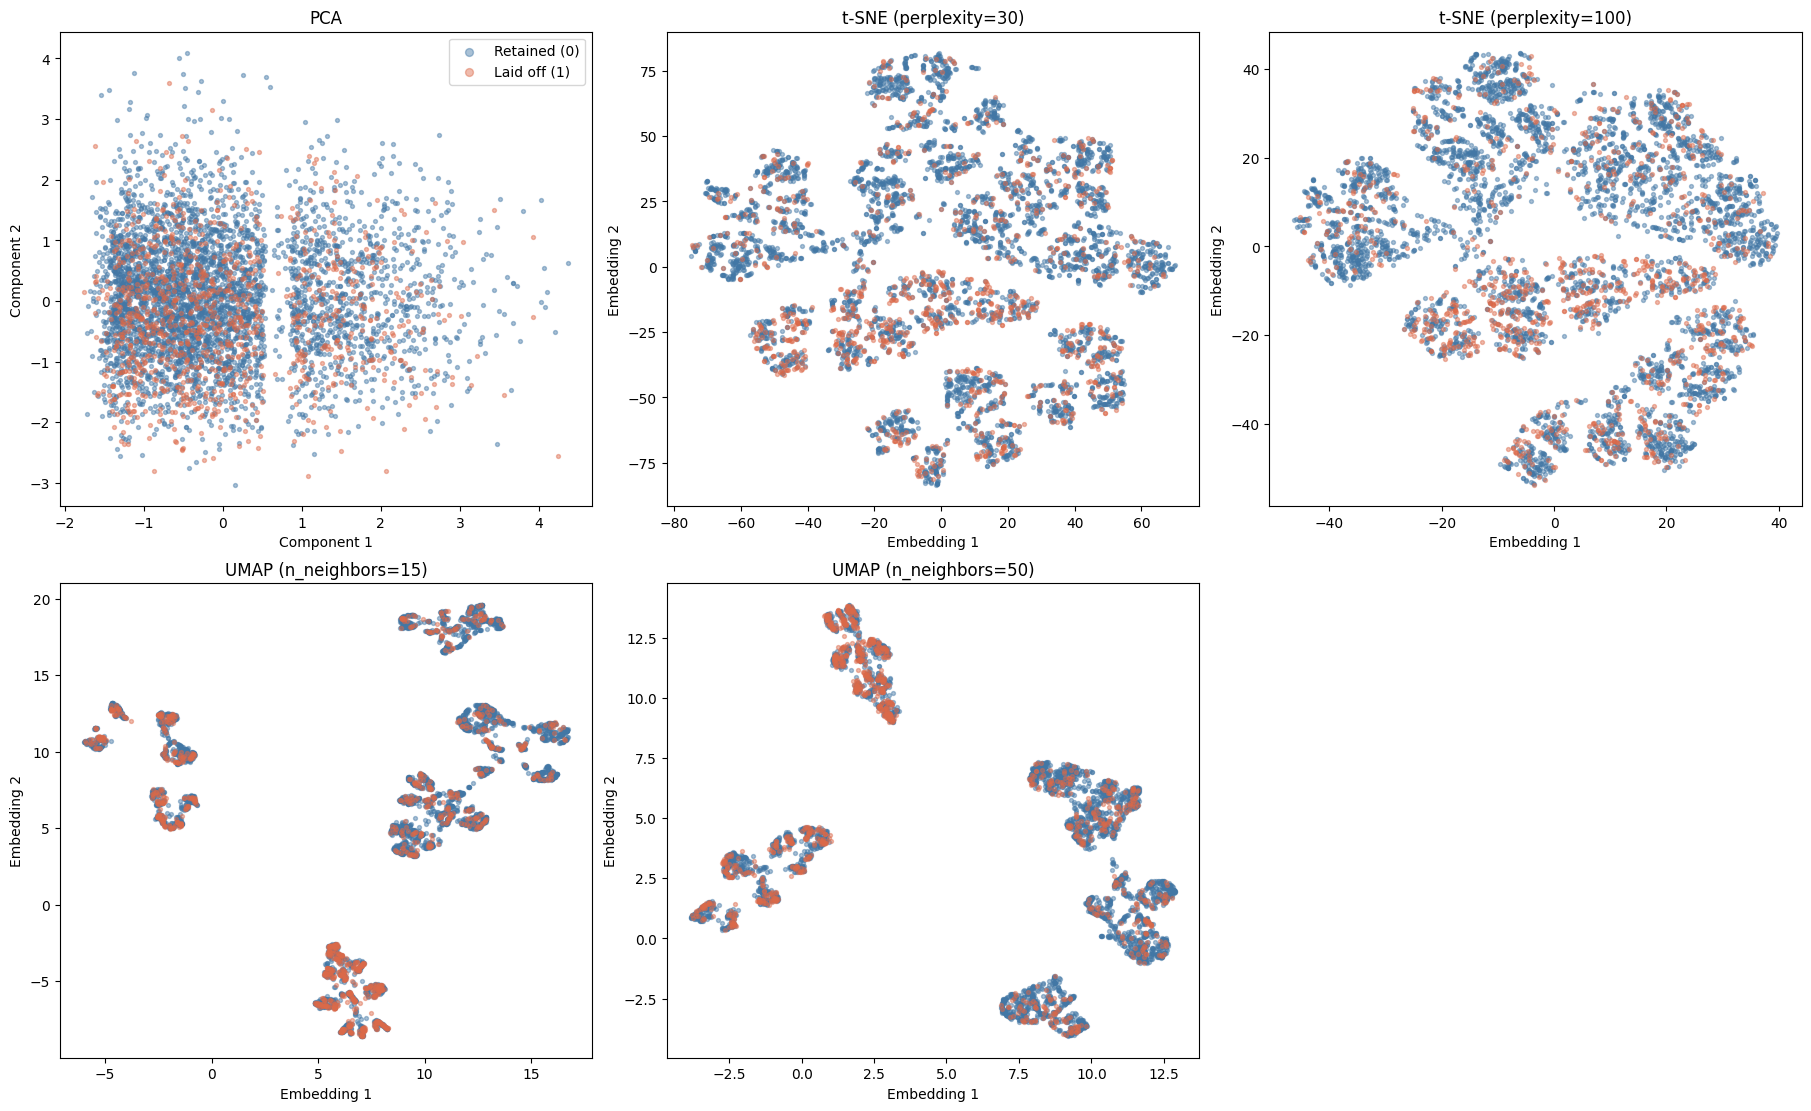

In [26]:
import inspect

from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
import umap

y_train_array = np.asarray(y_train)

sample_size = min(5_000, len(y_train_array))
all_indices = np.arange(len(y_train_array))

if sample_size < len(all_indices):
    sample_indices, _ = train_test_split(
        all_indices,
        train_size=sample_size,
        stratify=y_train_array,
        random_state=42,
    )
else:
    sample_indices = all_indices

X_sample = X_train_ready[sample_indices]
y_sample = y_train_array[sample_indices]

print(f"Projection sample: {len(y_sample):,} training employees")
print(f"Sample layoff rate: {y_sample.mean():.1%}")

projections = {
    "PCA": pca.transform(X_sample)[:, :2],
}

# scikit-learn renamed n_iter to max_iter; accept either installed version.
iteration_arg = (
    "max_iter" if "max_iter" in inspect.signature(TSNE).parameters
    else "n_iter"
)

for perplexity in (30, 100):
    model = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=42,
        **{iteration_arg: 1000},
    )
    projections[f"t-SNE (perplexity={perplexity})"] = (
        model.fit_transform(X_sample)
    )

for n_neighbors in (15, 50):
    model = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=0.1,
        random_state=42,
    )
    projections[f"UMAP (n_neighbors={n_neighbors})"] = (
        model.fit_transform(X_sample)
    )

fig, axes = plt.subplots(2, 3, figsize=(18, 11), constrained_layout=True)

for ax, (title, coordinates) in zip(axes.flat, projections.items()):
    for cls, label, color in [
        (0, "Retained (0)", "#4277a5"),
        (1, "Laid off (1)", "#dc6949"),
    ]:
        mask = y_sample == cls
        ax.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=8,
            alpha=0.45,
            c=color,
            label=label,
            rasterized=True,
        )

    ax.set_title(title)
    ax.set_xlabel("Component 1" if title == "PCA" else "Embedding 1")
    ax.set_ylabel("Component 2" if title == "PCA" else "Embedding 2")

for ax in list(axes.flat)[len(projections):]:
    ax.set_visible(False)

axes.flat[0].legend(markerscale=2)
plt.savefig("./figures/figure7.png", dpi=150)
plt.show()

PCA was fitted to the preprocessed training features. The first two principal components explain approximately 36% of the total variance; around nine components are needed to retain 80%, and fourteen to retain 90%. PC1 is driven mainly by standardized salary (loading 0.888), with additional contributions from `high_salary` (0.328) and seniority level: junior has a negative loading (−0.228), while staff and lead have positive loadings. PC1 therefore primarily represents a salary and seniority direction. PC2 is driven mainly by performance rating (0.788) and tenure (0.606), with a smaller negative contribution from `on_pip` (−0.096). These loadings describe directions of variation in the input features; they do not measure associations with the layoff target.

In the two-dimensional PCA projection, retained and laid-off employees overlap substantially. t-SNE and UMAP reveal several local groups that are less apparent in PCA, but both target classes appear within most groups. The groups also change in shape and arrangement across the two perplexity values and the two `n_neighbors` values. Thus, the nonlinear projections reveal local feature structure without showing a clear separation between laid-off and retained employees. Their cluster sizes and intercluster distances should not be read as literal group prevalence or distances in the original feature space.

C. Pipeline

The preprocessing pipeline was fitted on the training split only (18,000 employees) and then applied without refitting to the validation and test splits (6,000 employees each). A `ColumnTransformer` within a `Pipeline` applied median imputation and standardization to three numerical features, explicit missing-category imputation and one-hot encoding to four categorical features, and most-frequent imputation to six binary features. The resulting matrices each have 29 features, in the same order: `X_train_ready` has shape (18,000, 29), `X_val_ready` has shape (6,000, 29), and `X_test_ready` has shape (6,000, 29). No `NaN` values remain in any split. The pipeline reports the names of all 29 output features, consisting of three standardized numerical columns, twenty one-hot category columns, and six binary columns. The target `laid_off` and identifier `employee_id` are excluded from the input features.